# Plotting


In this notebook we plot the output from Code 

In [82]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import plot_utils as pltutils
eV = 1.60218e-12
traj = np.loadtxt('./../Code/trajectory.dat')
parsec = 3.086e+18
zmin = np.min(traj[:,0])
zmax = np.max(traj[:,0])

## Synchrotron SED

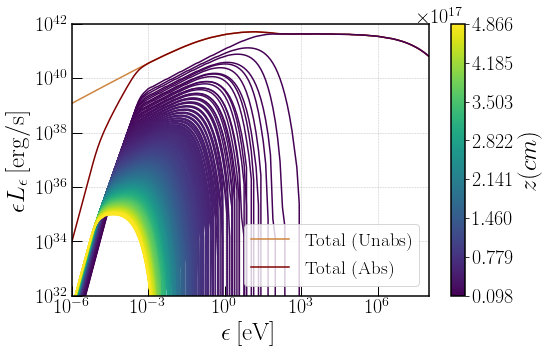

In [90]:
# Load the output of the jet synchrotron SED
synsed_output = np.loadtxt('./../Code/SEDsyn_jet.dat')
synsed_ord = np.loadtxt('./../Code/SEDsyn_cuts_ord.dat')


# Define quantities
nu  = synsed_output[:,0]
tot_un = synsed_output[:,3]
tot_abs = synsed_output[:,4]

# Init plot
fig, ax= plt.subplots(1,1, figsize=(8,5))
colors = pltutils.iar_aut

# Plot total SED
ax.loglog(nu,tot_un, label='Total (Unabs)', color=colors[0])
ax.loglog(nu,tot_abs, label='Total (Abs)', color=colors[1])

# Plot individual curves for different Z
nu = synsed_ord[:,0]
zec = synsed_ord[:,2]
nu = np.reshape(nu,(512,150))
zec = np.reshape(zec,(512,150))
colormap, sm = pltutils.color_from_cmap('viridis',len(nu), vmin=int(zmin), vmax=int(zmax))
for i in range(len(nu)):
    ax.loglog(nu[i],zec[i], color=colormap[i])

plt.colorbar(sm, ticks=np.linspace(zmin, zmax, 8), label='$z(cm)$')
# Set limits#
ax.set_ylim([1e32,1e42])
ax.set_xlim([1e-6,1e8])

# Legends and labels
plt.legend(loc='lower right', fontsize=19)
ax.set_xlabel('$\\epsilon \: [\\rm eV]$')
ax.set_ylabel('$\\epsilon L_{\\epsilon} \: [\\rm erg/s]$')

# Set the style of the plot
pltutils.luc_std_plot(ax)

plt.show()

# N(E) distribution

/opt/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:27: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
/opt/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:28: UserWarning: Data has no positive values, and therefore cannot be log-scaled.


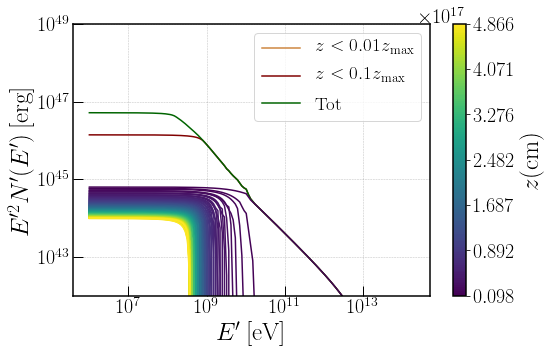

In [101]:
# Load the output of the jet synchrotron SED
NE_output = np.loadtxt('./../Code/NE_jet.dat')
NE_output_ord = np.loadtxt('./../Code/NE_cuts_ord.dat')


# Define quantities for total N
nu  = NE_output[:,0]
z1  = NE_output[:,1]
z2  = NE_output[:,2]
tot = NE_output[:,3]

# Define quantities for N cuts
nucut = NE_output_ord[:,0]
necut = NE_output_ord[:,1]
# take diimensions from array
n = int( np.max(NE_output_ord[:,2]) )
m = int( len(NE_output_ord[:,2]) / n )
# reshape arrays
nucut = np.reshape(nucut,(n,m))
necut = np.reshape(necut,(n,m))

# Init plot
fig, ax= plt.subplots(1,1, figsize=(8,5))
colors = pltutils.iar_aut

# Plot total SED
ax.loglog(nu,z1, label='$z< 0.01 z_{\\rm max}$', color=colors[0])
ax.loglog(nu,z2, label='$z< 0.1 z_{\\rm max}$', color=colors[1])
ax.loglog(nu,tot, label='Tot', color=colors[2])

# Plot individual curves for different Z

colormap, sm = pltutils.color_from_cmap('viridis',len(nu), vmin=zmin, vmax=zmax)
for i in range(len(nu)):
    ax.loglog(nucut[i]/eV,necut[i]*nucut[i]**2, color=colormap[i])

plt.colorbar(sm, ticks=np.linspace(zmin, zmax, 7), label='$z(\\rm cm)$')
# Set limits#
ax.set_ylim([1e42,1e49])
#ax.set_xlim([1e-6,1e8])

# Legends and labels
plt.legend(loc='upper right', fontsize=19)
ax.set_xlabel('$E\' \: [\\rm eV]$')
ax.set_ylabel('$E\'^2 N \' (E\') \: [\\rm erg]$')

# Set the style of the plot
pltutils.luc_std_plot(ax)
plt.show()